# Lab 12 · Training an Imaging Model
## From scratch versus transfer learning

**Completed lab · PneumoniaMNIST 64 × 64 · Seed 42**

The analysis compares two baselines, a small CNN trained from scratch, and three ImageNet-pretrained ResNet-18 variants. I ran the full schedule on CPU. The model and threshold were selected using validation data before any test predictions.

| Frozen evaluation | Result |
|---|---|
| Model | ResNet-18 fine-tuned with augmentation |
| Validation sensitivity target | 95% |
| Frozen threshold | 0.668372 |
| Test AUROC | 0.9882 |
| 95% image bootstrap interval | 0.9813–0.9937 |
| Test sensitivity / specificity | 99.7% / 87.2% |

This is a benchmark on low-resolution pediatric chest X-ray images for an educational classification exercise. Run from top to bottom in an environment with PyTorch, torchvision, NumPy, pandas, scikit-learn, and Matplotlib. The first run downloads the data and pretrained weights if they are absent. The final cell writes the results CSV and, for a neural model, the chosen checkpoint.

## Setup and data integrity

In [1]:
import hashlib
import os
import random
import time
import urllib.request
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from torch.utils.data import DataLoader, TensorDataset
from torchvision.models import ResNet18_Weights, resnet18

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(min(8, len(os.sched_getaffinity(0))) if hasattr(os, "sched_getaffinity") else 4)
ON_KAGGLE = Path("/kaggle/working").is_dir()
DATA_DIR = (Path("/kaggle/working") if ON_KAGGLE else Path.cwd()) / "lab12_data"
DATA_DIR.mkdir(parents=True, exist_ok=True)
torch.hub.set_dir(str(DATA_DIR / "torch" / "hub"))
print(f"torch {torch.__version__} | torchvision {torchvision.__version__} | scikit-learn {sklearn.__version__}")
print(f"Device: {DEVICE} | Seed: {SEED}")

def check(description, condition):
    assert condition, description
    print(f"PASS · {description}")

torch 2.7.1+cpu | torchvision 0.22.1+cpu | scikit-learn 1.8.0
Device: cpu | Seed: 42


In [2]:
DATA_URL = "https://zenodo.org/records/10519652/files/pneumoniamnist_64.npz?download=1"
DATA_MD5 = "8f4eceb4ccffa70c672198ea285246c6"
attached = sorted(Path("/kaggle/input").rglob("pneumoniamnist_64.npz")) if ON_KAGGLE else []
DATA_FILE = attached[0] if attached else DATA_DIR / "pneumoniamnist_64.npz"
if not DATA_FILE.exists():
    temporary = DATA_FILE.with_suffix(".download")
    urllib.request.urlretrieve(DATA_URL, temporary)
    if hashlib.md5(temporary.read_bytes()).hexdigest() != DATA_MD5:
        temporary.unlink()
        raise ValueError("Downloaded data did not match the published checksum.")
    temporary.replace(DATA_FILE)
check("PneumoniaMNIST 64 checksum", hashlib.md5(DATA_FILE.read_bytes()).hexdigest() == DATA_MD5)
SPLITS = ("train", "val", "test")
with np.load(DATA_FILE) as data:
    IMAGES = {split: data[f"{split}_images"] for split in SPLITS}
    LABELS = {split: data[f"{split}_labels"].ravel().astype(int) for split in SPLITS}
CLASS_NAMES = {0: "Normal", 1: "Pneumonia"}
for split, size in zip(SPLITS, (4708, 524, 624)):
    check(f"{split}: {size} grayscale images with binary labels",
          IMAGES[split].shape == (size, 64, 64)
          and IMAGES[split].dtype == np.uint8
          and LABELS[split].shape == (size,)
          and np.array_equal(np.unique(LABELS[split]), [0, 1]))

PASS · PneumoniaMNIST 64 checksum
PASS · train: 4708 grayscale images with binary labels
PASS · val: 524 grayscale images with binary labels
PASS · test: 624 grayscale images with binary labels


## Part 1 · Know the data before training

The public file uses labels 0 for normal and 1 for pneumonia. MedMNIST created the 9:1 train and validation split from the source training pool and used the source's held-out split for test. The split audit uses test labels only for the requested counts and integrity checks. Model fitting, epoch selection, and threshold selection use train or validation data. [MedMNIST metadata](https://github.com/MedMNIST/MedMNIST/blob/main/medmnist/info.py)

In [3]:
def split_summary():
    rows = []
    for split in SPLITS:
        y = LABELS[split]
        rows.append({
            "split": split, "images": len(y), "normal": int((y == 0).sum()),
            "pneumonia": int((y == 1).sum()), "pneumonia_fraction": float(y.mean()),
        })
    return pd.DataFrame(rows)

summary = split_summary()
display(summary.round(4))
check("4,708 training images and 3,494 training positives",
      summary.loc[0, "images"] == 4708 and summary.loc[0, "pneumonia"] == 3494)

,split,images,normal,pneumonia,pneumonia_fraction
0,train,4708,1214,3494,0.7421
1,val,524,135,389,0.7424
2,test,624,234,390,0.6250


PASS · 4,708 training images and 3,494 training positives


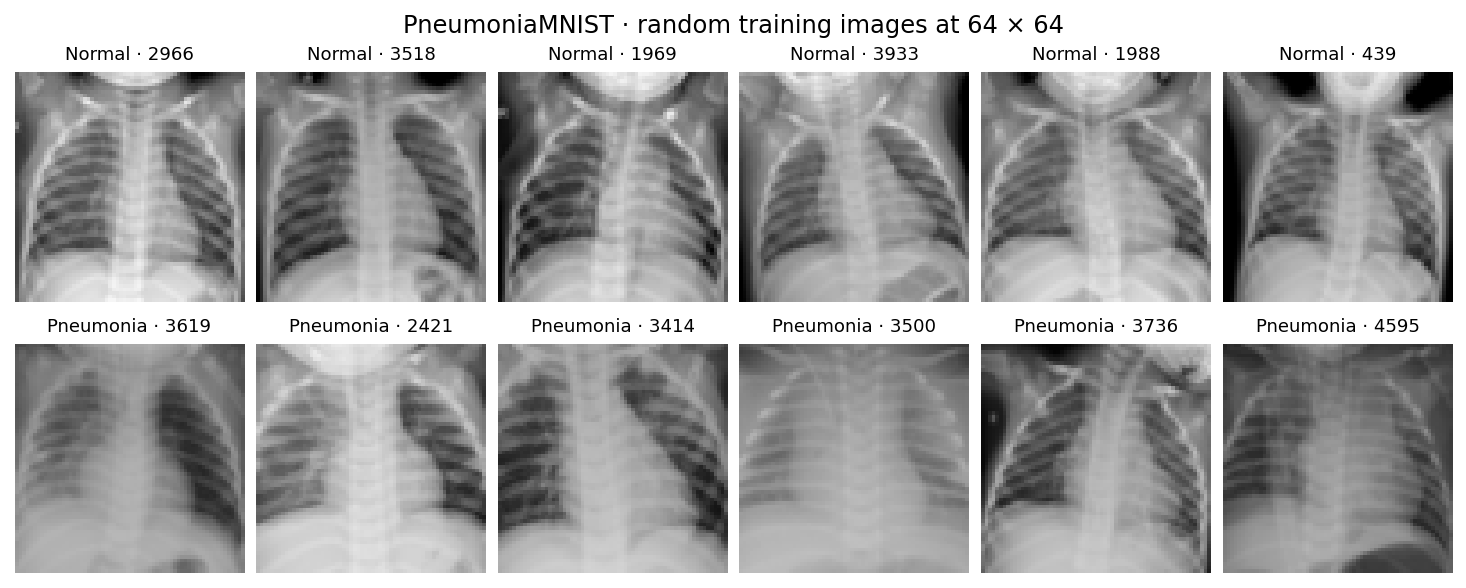

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(10, 4), layout="constrained")
rng = np.random.default_rng(SEED)
for row, label in enumerate((0, 1)):
    indices = rng.choice(np.flatnonzero(LABELS["train"] == label), size=6, replace=False)
    for ax, index in zip(axes[row], indices):
        ax.imshow(IMAGES["train"][index], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{CLASS_NAMES[label]} · {index}", fontsize=9)
        ax.axis("off")
fig.suptitle("PneumoniaMNIST · random training images at 64 × 64")
plt.show()

### Exercise 1.2 · Interpret the split

One row represents one chest X-ray image, so 4,708 training images do not establish that there were 4,708 distinct children. There are no patient IDs in the files, so repeat images from one child and patient-level separation cannot be verified. A random validation subset from the same source pool can look optimistic because it shares acquisition and population characteristics, and related images could cross the split. PPV can change with the positive fraction even when sensitivity and specificity stay fixed. Pneumonia accounts for 74.2% of validation images and 62.5% of test images, and neither figure estimates the prevalence among children attending an arbitrary clinic. Applying the model to a clinic with a different prevalence can change how often an alert is correct and how many reviews it generates.

## Part 2 · Metrics and baselines

### Exercise 2.1 · Metrics at a threshold

In [5]:
def binary_metrics(y_true, p, threshold=0.5):
    y_true = np.asarray(y_true)
    p = np.asarray(p)
    positive = p >= threshold
    diseased = y_true == 1
    tp = int((positive & diseased).sum())
    fn = int((~positive & diseased).sum())
    tn = int((~positive & ~diseased).sum())
    fp = int((positive & ~diseased).sum())

    def divide(numerator, denominator):
        return numerator / denominator if denominator else None

    return {
        "auroc": float(roc_auc_score(y_true, p)) if len(np.unique(y_true)) == 2 else None,
        "sensitivity": divide(tp, tp + fn), "specificity": divide(tn, tn + fp),
        "ppv": divide(tp, tp + fp), "npv": divide(tn, tn + fn),
        "accuracy": divide(tp + tn, len(y_true)), "tp": tp, "fn": fn, "tn": tn, "fp": fp,
    }

toy = binary_metrics([1, 1, 1, 0, 0], [0.9, 0.8, 0.2, 0.6, 0.1])
check("toy sensitivity = 2/3", toy["sensitivity"] == 2 / 3)
check("toy specificity = 1/2", toy["specificity"] == 0.5)
check("toy PPV = 2/3", toy["ppv"] == 2 / 3)
check("toy NPV = 1/2", toy["npv"] == 0.5)
check("undefined NPV is None", binary_metrics([0, 1], [0.7, 0.7])["npv"] is None)
display(pd.Series(toy, name="Toy example"))

PASS · toy sensitivity = 2/3
PASS · toy specificity = 1/2
PASS · toy PPV = 2/3
PASS · toy NPV = 1/2
PASS · undefined NPV is None


auroc          0.833333
sensitivity    0.666667
specificity    0.500000
ppv            0.666667
npv            0.500000
accuracy       0.600000
tp             2.000000
fn             1.000000
tn             1.000000
fp             1.000000
Name: Toy example, dtype: float64

The constant baseline predicts the training positive fraction. Pixel logistic regression averages 2 × 2 blocks to 32 × 32, scales pixels to [0, 1], and fits a regularized linear classifier on 1,024 values per image. The baseline results and all comparison metrics through Part 4 use validation data.

In [6]:
VAL_PRED = {}
MODELS = {}

def val_table():
    return pd.DataFrame([
        {"model": name, **binary_metrics(LABELS["val"], p)} for name, p in VAL_PRED.items()
    ])[["model", "auroc", "sensitivity", "specificity", "ppv", "npv", "accuracy"]]

class TrivialBaseline:
    def __init__(self, train_labels):
        self.rate = float(np.mean(train_labels))

    def predict(self, images):
        return np.full(len(images), self.rate)

def pixels_32(images):
    pixels = images.astype(np.float32) / 255
    return pixels.reshape(len(pixels), 32, 2, 32, 2).mean(axis=(2, 4)).reshape(len(pixels), -1)

class PixelLogReg:
    def __init__(self):
        self.clf = LogisticRegression(C=0.1, max_iter=2000)

    def fit(self, images, labels):
        self.clf.fit(pixels_32(images), labels)
        return self

    def predict(self, images):
        return self.clf.predict_proba(pixels_32(images))[:, 1]

MODELS["trivial"] = TrivialBaseline(LABELS["train"])
MODELS["logreg_pixels"] = PixelLogReg().fit(IMAGES["train"], LABELS["train"])
for name, model in MODELS.items():
    VAL_PRED[name] = model.predict(IMAGES["val"])
display(val_table().round(4))

,model,auroc,sensitivity,specificity,ppv,npv,accuracy
0,trivial,0.5000,1.0000,0.0000,0.7424,NaN,0.7424
1,logreg_pixels,0.9891,0.9743,0.9037,0.9668,0.9242,0.9561


### Exercise 2.2 · Interpret the baselines

At a 0.5 threshold the constant baseline has **74.2% accuracy, 100% sensitivity, and 0% specificity** because it labels every image positive. That accuracy simply reflects the majority class, and the model neither identifies normal images nor prioritizes one image over another. Its AUROC is 0.5 because every positive–negative pair is tied. Pixel logistic regression reaches **0.9891 AUROC** at 64 × 64 source resolution, indicating strong separation within this validation split even with simple intensity features, which may also capture acquisition or dataset cues.

## Part 3 · Small CNN from scratch

The CNN uses one input channel, three convolution blocks, global average pooling, and a binary logit. Its normalization and positive-class weight are calculated from the training split. Adam uses weighted binary cross-entropy for training, while the plotted validation loss is unweighted. Compare trends across epochs rather than the absolute sizes of the two losses.

In [7]:
def image_tensor(images):
    return torch.from_numpy(images).float().div(255).unsqueeze(1)

TENSORS = {s: image_tensor(IMAGES[s]) for s in ("train", "val")}
TARGETS = {s: torch.from_numpy(LABELS[s]).float() for s in ("train", "val")}
TRAIN_MEAN = TENSORS["train"].mean().item()
TRAIN_STD = TENSORS["train"].std().item()
n_pos = int(LABELS["train"].sum())
n_neg = len(LABELS["train"]) - n_pos
POS_WEIGHT = torch.tensor([n_neg / n_pos], device=DEVICE)
print(f"Train tensor {tuple(TENSORS['train'].shape)} | mean {TRAIN_MEAN:.4f} | std {TRAIN_STD:.4f}")
print(f"Positive loss weight: {n_neg}/{n_pos} = {POS_WEIGHT.item():.4f}")

Train tensor (4708, 1, 64, 64) | mean 0.5717 | std 0.1741
Positive loss weight: 1214/3494 = 0.3475


In [8]:
class SmallCNN(nn.Module):
    def __init__(self, mean, std):
        super().__init__()
        self.register_buffer("mean", torch.tensor(mean))
        self.register_buffer("std", torch.tensor(std))

        def block(c_in, c_out):
            return nn.Sequential(
                nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out),
                nn.ReLU(), nn.MaxPool2d(2),
            )

        self.features = nn.Sequential(block(1, 16), block(16, 32), block(32, 64), nn.AdaptiveAvgPool2d(1))
        self.head = nn.Linear(64, 1)

    def forward(self, x):
        return self.head(self.features((x - self.mean) / self.std).flatten(1)).squeeze(1)

def count_params(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if not trainable_only or p.requires_grad)

@torch.no_grad()
def predict_proba(model, x, batch_size=128):
    model.eval()
    return torch.cat([torch.sigmoid(model(batch.to(DEVICE))).cpu() for batch in x.split(batch_size)]).numpy()

def train_model(model, epochs, lr, augment=None, batch_size=128, weight_decay=1e-4):
    set_seed()
    model = model.to(device=DEVICE, memory_format=torch.channels_last)
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=weight_decay)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=POS_WEIGHT)
    loader = DataLoader(TensorDataset(TENSORS["train"], TARGETS["train"]),
                        batch_size=batch_size, shuffle=True, generator=torch.Generator().manual_seed(SEED))
    rows, best_auc, best_state = [], -np.inf, None
    for epoch in range(1, epochs + 1):
        started = time.perf_counter()
        model.train()
        running_loss = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            if augment is not None:
                xb = augment(xb)
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * len(xb)
        val_proba = predict_proba(model, TENSORS["val"])
        val_loss = F.binary_cross_entropy(torch.from_numpy(val_proba).clamp(1e-7, 1 - 1e-7), TARGETS["val"]).item()
        auc = float(roc_auc_score(LABELS["val"], val_proba))
        train_loss = running_loss / len(TENSORS["train"])
        elapsed = time.perf_counter() - started
        rows.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, "val_auroc": auc, "seconds": elapsed})
        if auc > best_auc:
            best_auc, best_state = auc, deepcopy(model.state_dict())
        print(f"Epoch {epoch:2} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | val AUROC {auc:.4f} | {elapsed:.1f}s", flush=True)
    model.load_state_dict(best_state)
    history = pd.DataFrame(rows)
    print(f"Kept epoch {history.val_auroc.idxmax() + 1} (validation AUROC {best_auc:.4f})")
    return model, history

class TorchPredictor:
    def __init__(self, model):
        self.model = model

    def predict(self, images):
        return predict_proba(self.model, image_tensor(images))

def plot_history(history, title):
    fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.3), layout="constrained")
    left.plot(history.epoch, history.train_loss, "o-", label="Training (weighted)")
    left.plot(history.epoch, history.val_loss, "o-", label="Validation (unweighted)")
    left.set(xlabel="Epoch", ylabel="Binary cross-entropy")
    left.legend(fontsize=8)
    right.plot(history.epoch, history.val_auroc, "o-", color="#287d6e")
    best = history.loc[history.val_auroc.idxmax()]
    right.scatter(best.epoch, best.val_auroc, marker="D", color="#b65435", zorder=4, label="Kept epoch")
    right.set(xlabel="Epoch", ylabel="Validation AUROC")
    right.legend(fontsize=8)
    for ax in (left, right):
        ax.set_xticks(history.epoch)
        ax.grid(alpha=0.2)
    fig.suptitle(title)
    plt.show()

def register_model(name, model):
    MODELS[name] = TorchPredictor(model)
    VAL_PRED[name] = MODELS[name].predict(IMAGES["val"])

SmallCNN trainable parameters: 23,585
Epoch  1 | train loss 0.1892 | val loss 0.3842 | val AUROC 0.9596 | 2.1s
Epoch  2 | train loss 0.1351 | val loss 0.2274 | val AUROC 0.9676 | 1.9s
Epoch  3 | train loss 0.1137 | val loss 0.2938 | val AUROC 0.9704 | 1.9s
Epoch  4 | train loss 0.0970 | val loss 0.1727 | val AUROC 0.9800 | 1.9s
Epoch  5 | train loss 0.0870 | val loss 0.2434 | val AUROC 0.9741 | 2.1s
Epoch  6 | train loss 0.0823 | val loss 0.1554 | val AUROC 0.9836 | 1.8s
Epoch  7 | train loss 0.0724 | val loss 0.2114 | val AUROC 0.9781 | 2.1s
Epoch  8 | train loss 0.0656 | val loss 0.2042 | val AUROC 0.9888 | 2.0s
Epoch  9 | train loss 0.0753 | val loss 0.1553 | val AUROC 0.9901 | 2.1s
Epoch 10 | train loss 0.0601 | val loss 0.1955 | val AUROC 0.9873 | 2.0s
Epoch 11 | train loss 0.0645 | val loss 0.1219 | val AUROC 0.9890 | 2.2s
Epoch 12 | train loss 0.0606 | val loss 0.1185 | val AUROC 0.9894 | 1.9s
Epoch 13 | train loss 0.0564 | val loss 0.2677 | val AUROC 0.9890 | 2.1s
Epoch 14 | tr

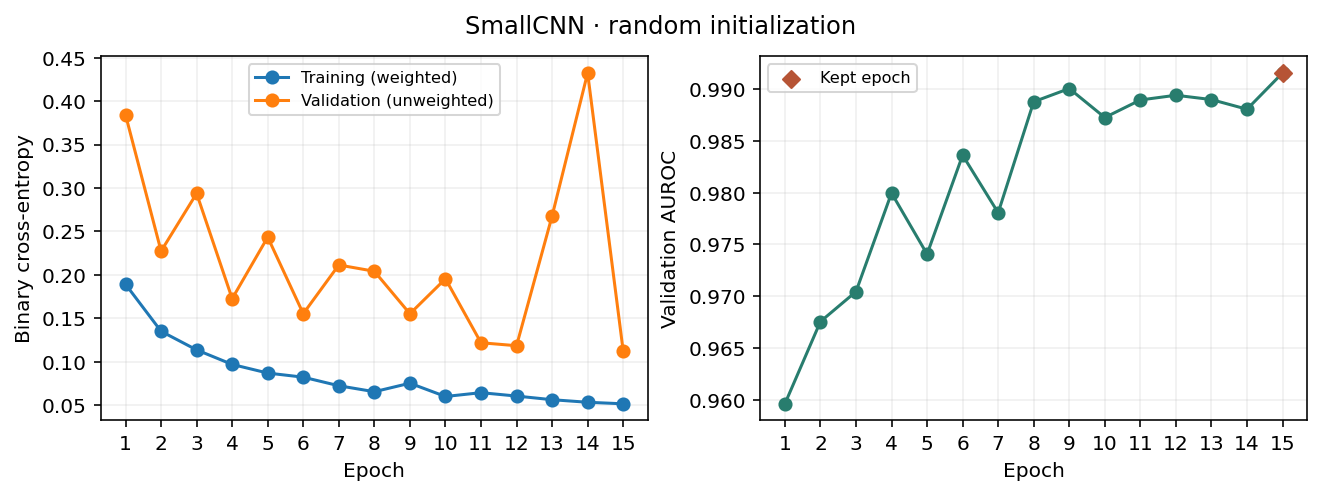

,model,auroc,sensitivity,specificity,ppv,npv,accuracy
0,trivial,0.5000,1.0000,0.0000,0.7424,NaN,0.7424
1,logreg_pixels,0.9891,0.9743,0.9037,0.9668,0.9242,0.9561
2,cnn_scratch,0.9916,0.9871,0.8667,0.9552,0.9590,0.9561


In [9]:
set_seed()
cnn = SmallCNN(TRAIN_MEAN, TRAIN_STD)
print(f"SmallCNN trainable parameters: {count_params(cnn, trainable_only=True):,}")
cnn, hist_cnn = train_model(cnn, epochs=15, lr=1e-3)
register_model("cnn_scratch", cnn)
plot_history(hist_cnn, "SmallCNN · random initialization")
display(val_table().round(4))

### Exercise 3.1 · Interpret the learning curves

Epoch 15 was kept because it had the highest validation AUROC (0.9916), which in this run happened to be the final epoch. From epochs 13 to 14, training loss fell from 0.0564 to 0.0534 while validation loss rose from 0.2677 to 0.4324, consistent with a generalization gap or validation instability rather than a smooth, sustained deterioration. The CNN scored 0.9916 AUROC versus 0.9891 for the pixel baseline, a difference of +0.0025. This one split does not show a gain large enough on its own to justify the additional model complexity. With 23,585 trainable parameters and 4,708 training images, the CNN has room to learn source-specific patterns, making checkpoint selection and independent evaluation important.

## Part 4 · Transfer learning with ResNet-18

Resize grayscale images to 128 × 128 by bilinear interpolation, replicate the single channel three times, then apply ImageNet normalization. Replace the pretrained classifier with a one-logit head. [Torchvision ResNet-18 documentation](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html)

### Exercise 4.1 · Freeze the backbone

In [10]:
class PretrainedResNet(nn.Module):
    def __init__(self, weights=ResNet18_Weights.IMAGENET1K_V1, size=128):
        super().__init__()
        self.size = size
        self.backbone = resnet18(weights=weights)
        self.backbone.fc = nn.Linear(self.backbone.fc.in_features, 1)
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        x = F.interpolate(x, size=(self.size, self.size), mode="bilinear", align_corners=False).expand(-1, 3, -1, -1)
        x = ((x - self.mean) / self.std).contiguous(memory_format=torch.channels_last)
        return self.backbone(x).squeeze(1)

def set_backbone_trainable(model, trainable):
    model.backbone.requires_grad_(trainable)
    model.backbone.fc.requires_grad_(True)

set_seed()
resnet = PretrainedResNet()
set_backbone_trainable(resnet, False)
check("only 513 head parameters are trainable", count_params(resnet, trainable_only=True) == 513)
print(f"ResNet-18 total parameters: {count_params(resnet):,}")

PASS · only 513 head parameters are trainable
ResNet-18 total parameters: 11,177,025


### Stage A · Feature extraction

Only the head's 513 parameters receive gradients. As in the starter lab, the backbone still runs in training mode during the training batches, so its batch-normalization running statistics adapt.

Epoch  1 | train loss 0.2226 | val loss 0.4842 | val AUROC 0.9508 | 11.3s
Epoch  2 | train loss 0.1288 | val loss 0.2971 | val AUROC 0.9707 | 11.3s
Epoch  3 | train loss 0.1091 | val loss 0.2096 | val AUROC 0.9735 | 11.3s
Epoch  4 | train loss 0.0979 | val loss 0.2093 | val AUROC 0.9754 | 13.8s
Epoch  5 | train loss 0.0926 | val loss 0.1950 | val AUROC 0.9774 | 12.5s
Kept epoch 5 (validation AUROC 0.9774)


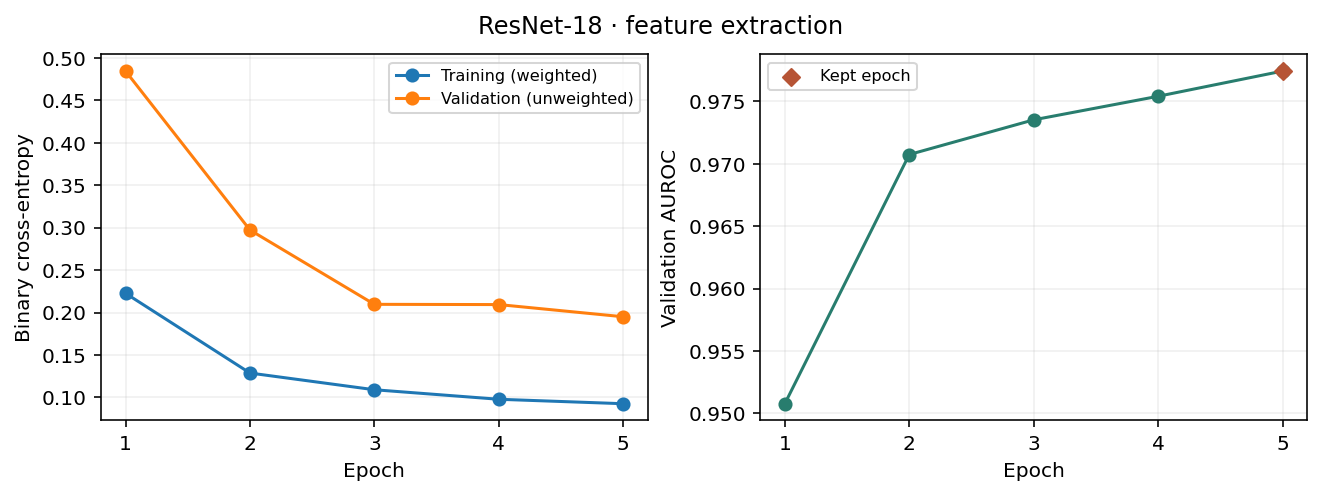

In [11]:
resnet, hist_head = train_model(resnet, epochs=5, lr=1e-3)
register_model("resnet_features", resnet)
plot_history(hist_head, "ResNet-18 · feature extraction")

### Stage B · Fine-tuning without augmentation

Start from the best Stage A checkpoint and unfreeze every parameter. Use six epochs at a learning rate of 0.0001.

PASS · all ResNet-18 parameters trainable
Fine-tuning parameters: 11,177,025
Epoch  1 | train loss 0.0570 | val loss 0.1821 | val AUROC 0.9976 | 32.1s
Epoch  2 | train loss 0.0124 | val loss 0.0641 | val AUROC 0.9973 | 34.2s
Epoch  3 | train loss 0.0058 | val loss 0.0541 | val AUROC 0.9982 | 32.8s
Epoch  4 | train loss 0.0011 | val loss 0.0603 | val AUROC 0.9981 | 33.7s
Epoch  5 | train loss 0.0007 | val loss 0.0751 | val AUROC 0.9979 | 33.0s
Epoch  6 | train loss 0.0002 | val loss 0.0652 | val AUROC 0.9981 | 33.6s
Kept epoch 3 (validation AUROC 0.9982)


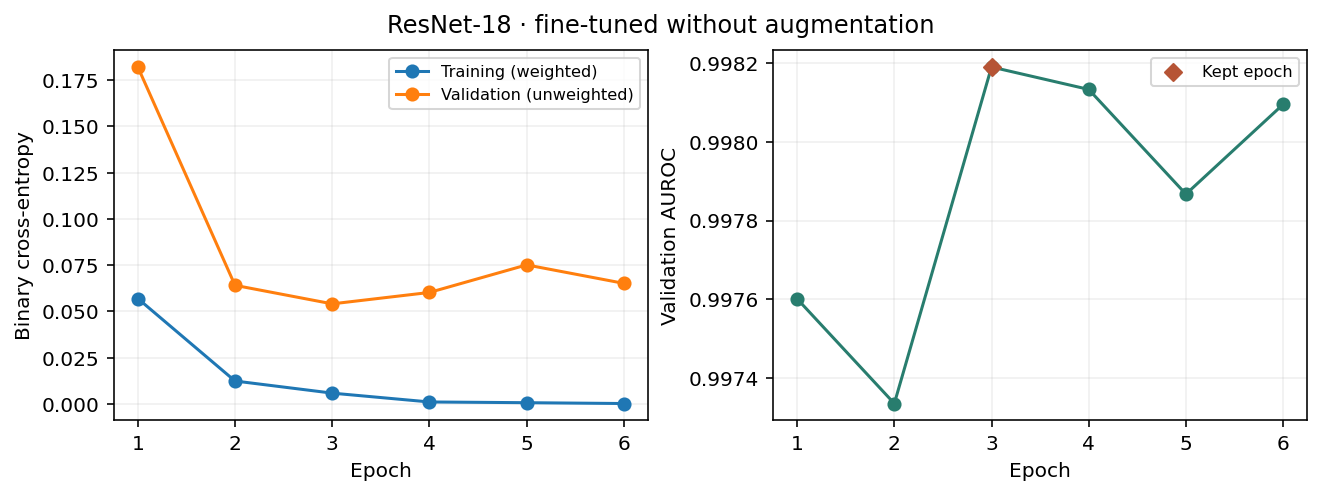

In [12]:
resnet_ft = deepcopy(resnet)
set_backbone_trainable(resnet_ft, True)
check("all ResNet-18 parameters trainable", count_params(resnet_ft, True) == count_params(resnet_ft))
print(f"Fine-tuning parameters: {count_params(resnet_ft, True):,}")
resnet_ft, hist_ft = train_model(resnet_ft, epochs=6, lr=1e-4)
register_model("resnet_finetuned", resnet_ft)
plot_history(hist_ft, "ResNet-18 · fine-tuned without augmentation")

### Exercise 4.2 · Choose training-only augmentations

The linked companion lecture returned 404. The settings below follow the exercise’s label-preservation criterion and were checked visually. [Medical image augmentation review](https://pmc.ncbi.nlm.nih.gov/articles/PMC10027281/)

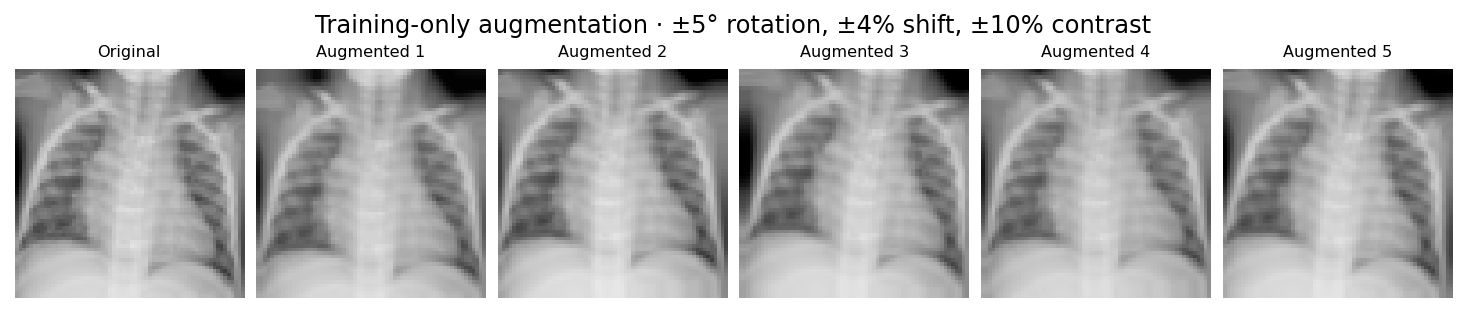

PASS · augmentation changes the example while keeping pixels in [0, 1]


In [13]:
def make_augment(max_rotation_deg=0, max_shift_frac=0, contrast=0, hflip=False):
    def augment(x):
        n = x.shape[0]
        angle = (torch.rand(n, device=x.device) * 2 - 1) * np.deg2rad(max_rotation_deg)
        shift = (torch.rand(n, 2, device=x.device) * 2 - 1) * max_shift_frac * 2
        flip = torch.where(torch.rand(n, device=x.device) < 0.5, -1.0, 1.0) if hflip else torch.ones_like(angle)
        cos, sin = torch.cos(angle), torch.sin(angle)
        theta = torch.stack([
            torch.stack([cos * flip, -sin, shift[:, 0]], dim=1),
            torch.stack([sin * flip, cos, shift[:, 1]], dim=1),
        ], dim=1)
        grid = F.affine_grid(theta, x.shape, align_corners=False)
        x = F.grid_sample(x, grid, padding_mode="border", align_corners=False)
        if contrast:
            factor = 1 + (torch.rand(n, 1, 1, 1, device=x.device) * 2 - 1) * contrast
            mean = x.mean(dim=(2, 3), keepdim=True)
            x = ((x - mean) * factor + mean).clamp(0, 1)
        return x
    return augment

AUGMENT_SETTINGS = {"max_rotation_deg": 5.0, "max_shift_frac": 0.04, "contrast": 0.10, "hflip": False}
augment = make_augment(**AUGMENT_SETTINGS)
set_seed()
example = TENSORS["train"][:1]
shown = augment(example.repeat(5, 1, 1, 1).to(DEVICE)).cpu()
fig, axes = plt.subplots(1, 6, figsize=(10, 2.1), layout="constrained")
for index, (ax, img) in enumerate(zip(axes, torch.cat([example, shown]))):
    ax.imshow(img[0], cmap="gray", vmin=0, vmax=1)
    ax.set_title("Original" if index == 0 else f"Augmented {index}", fontsize=8)
    ax.axis("off")
fig.suptitle("Training-only augmentation · ±5° rotation, ±4% shift, ±10% contrast")
plt.show()
check("augmentation changes the example while keeping pixels in [0, 1]",
      not torch.allclose(shown[0], example[0]) and bool((shown.ge(0) & shown.le(1)).all()))

### Stage C · Fine-tuning with augmentation

Use the same Stage A checkpoint, epoch budget and learning rate as Stage B. Apply transforms to training batches only.

Epoch  1 | train loss 0.0618 | val loss 0.1445 | val AUROC 0.9966 | 33.1s
Epoch  2 | train loss 0.0264 | val loss 0.0984 | val AUROC 0.9978 | 31.9s
Epoch  3 | train loss 0.0206 | val loss 0.0731 | val AUROC 0.9988 | 33.0s
Epoch  4 | train loss 0.0110 | val loss 0.0794 | val AUROC 0.9963 | 32.0s
Epoch  5 | train loss 0.0093 | val loss 0.0732 | val AUROC 0.9979 | 33.3s
Epoch  6 | train loss 0.0043 | val loss 0.0960 | val AUROC 0.9980 | 33.4s
Kept epoch 3 (validation AUROC 0.9988)


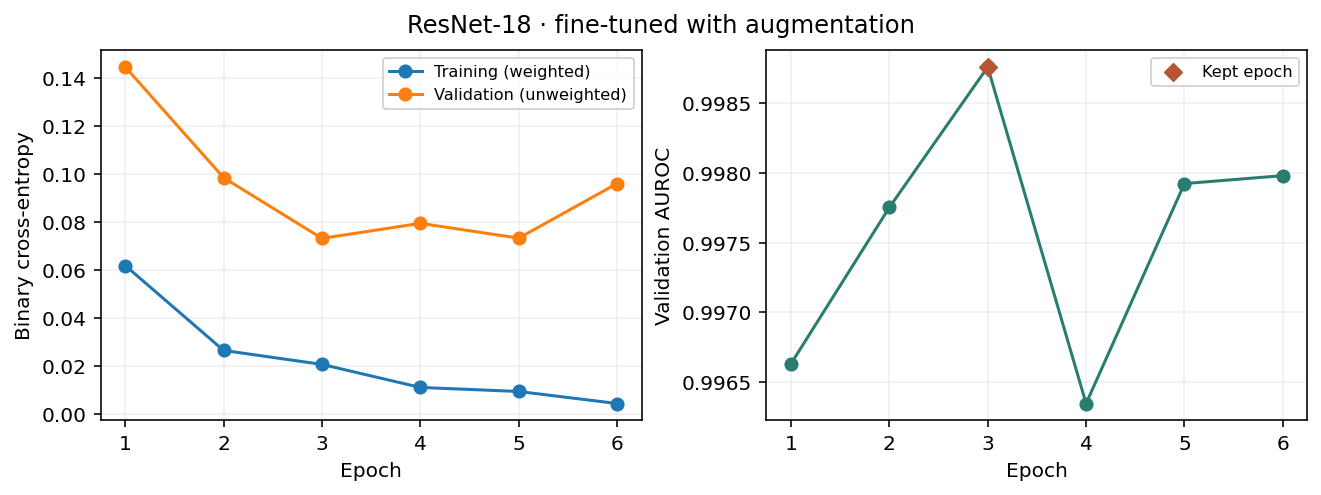

In [14]:
resnet_aug = deepcopy(resnet)
set_backbone_trainable(resnet_aug, True)
resnet_aug, hist_aug = train_model(resnet_aug, epochs=6, lr=1e-4, augment=augment)
register_model("resnet_finetuned_aug", resnet_aug)
plot_history(hist_aug, "ResNet-18 · fine-tuned with augmentation")

### Exercise 4.3 · Interpret transfer learning

I used rotation up to ±5° to mimic mild positioning variation, translation up to ±4% to mimic small shifts, and contrast scaling from 0.90 to 1.10 to vary intensity gently. I kept horizontal flips off to preserve laterality cues and the original left–right orientation of anatomy and markers. The five nonconstant models rank **ResNet-18 fine-tuned with augmentation (0.9988) > ResNet-18 fine-tuned without augmentation (0.9982) > SmallCNN from scratch (0.9916) > Pixel logistic regression (0.9891) > ResNet-18 feature extraction (0.9774)**, with the constant baseline last overall at 0.5000. The best transfer model differed from SmallCNN by +0.0072 AUROC, and fine-tuning without augmentation changed AUROC by +0.0208 versus head-only training. Augmentation changed AUROC by +0.0006 against otherwise matched fine-tuning, and six epochs, 524 validation images, and one training seed give limited grounds for treating a small difference as stable. Stage A can work with 513 trainable parameters because the pretrained backbone already represents visual features, while Stage B updates all 11,177,025 parameters. To isolate the effect of pretraining, compare the same ResNet-18 initialized from ImageNet and from random weights using matched optimization, preprocessing, epoch budget, augmentation, and multiple seeds.

## Part 5 · Choose, freeze, and test once

### Exercise 5.1 · Validation-only selection

Choose the highest unrounded validation AUROC. Use the highest observed score threshold that reaches at least 95% validation sensitivity. AUROC picks the ranking model, then sensitivity picks its operating point.

In [15]:
def threshold_for_sensitivity(y_true, p, target):
    if not 0 < target <= 1:
        raise ValueError("Target sensitivity must be in (0, 1].")
    _, sensitivity, thresholds = roc_curve(y_true, p, drop_intermediate=False)
    return float(thresholds[np.flatnonzero(sensitivity >= target)[0]])

validation_comparison = val_table().sort_values("auroc", ascending=False, kind="stable")
display(validation_comparison.round(4))
CHOSEN_MODEL = validation_comparison.iloc[0]["model"]
TARGET_SENSITIVITY = 0.95
THRESHOLD = threshold_for_sensitivity(LABELS["val"], VAL_PRED[CHOSEN_MODEL], TARGET_SENSITIVITY)
val_at_threshold = binary_metrics(LABELS["val"], VAL_PRED[CHOSEN_MODEL], THRESHOLD)
check("chosen threshold meets the validation sensitivity target",
      val_at_threshold["sensitivity"] >= TARGET_SENSITIVITY)
print(f"Frozen choice: {CHOSEN_MODEL} | cutoff {THRESHOLD:.8f} | validation sensitivity target {TARGET_SENSITIVITY:.0%}")
display(pd.DataFrame([val_at_threshold]).round(4))

,model,auroc,sensitivity,specificity,ppv,npv,accuracy
5,resnet_finetuned_aug,0.9988,0.9563,1.0000,1.0000,0.8882,0.9676
4,resnet_finetuned,0.9982,0.9897,0.9704,0.9897,0.9704,0.9847
2,cnn_scratch,0.9916,0.9871,0.8667,0.9552,0.9590,0.9561
1,logreg_pixels,0.9891,0.9743,0.9037,0.9668,0.9242,0.9561
3,resnet_features,0.9774,0.9332,0.8963,0.9629,0.8231,0.9237
0,trivial,0.5000,1.0000,0.0000,0.7424,NaN,0.7424


PASS · chosen threshold meets the validation sensitivity target
Frozen choice: resnet_finetuned_aug | cutoff 0.66837239 | validation sensitivity target 95%


,auroc,sensitivity,specificity,ppv,npv,accuracy,tp,fn,tn,fp
0,0.9988,0.9512,1.0,1.0,0.8766,0.9637,370,19,135,0


I chose **ResNet-18 fine-tuned with augmentation** because it had the highest validation AUROC (0.9988). The illustrative 95% sensitivity target prioritizes catching positive images for review, and the selected cutoff achieved 95.1% sensitivity. The corresponding specificity was 100.0%, so 0 of the 135 normal validation images would also be flagged.

### Frozen test evaluation

In [16]:
p_test = MODELS[CHOSEN_MODEL].predict(IMAGES["test"])
test_at_threshold = binary_metrics(LABELS["test"], p_test, THRESHOLD)
rng = np.random.default_rng(SEED)
boot = []
for _ in range(1000):
    indices = rng.integers(0, len(p_test), size=len(p_test))
    if np.unique(LABELS["test"][indices]).size == 2:
        boot.append(roc_auc_score(LABELS["test"][indices], p_test[indices]))
ci_low, ci_high = np.percentile(boot, [2.5, 97.5])

final = pd.DataFrame([
    {"set": "validation", "model": CHOSEN_MODEL, "threshold": THRESHOLD, **val_at_threshold},
    {"set": "test", "model": CHOSEN_MODEL, "threshold": THRESHOLD, **test_at_threshold},
])
pd.set_option("display.max_columns", 20)
display(final.round(4))
print(f"Test AUROC {test_at_threshold['auroc']:.4f} | 95% image bootstrap CI [{ci_low:.4f}, {ci_high:.4f}] ({len(boot)} resamples)")
results_file = DATA_DIR / "lab12_results.csv"
comparison_rows = pd.DataFrame([
    {"set": "validation", "model": name, "threshold": 0.5, **binary_metrics(LABELS["val"], p)}
    for name, p in VAL_PRED.items()
])
pd.concat([comparison_rows, final], ignore_index=True).to_csv(results_file, index=False)
if isinstance(MODELS[CHOSEN_MODEL], TorchPredictor):
    torch.save(MODELS[CHOSEN_MODEL].model.state_dict(), DATA_DIR / "lab12_chosen_model.pt")
print(f"Saved results to {results_file.name}.")

,set,model,threshold,auroc,sensitivity,specificity,ppv,npv,accuracy,tp,fn,tn,fp
0,validation,resnet_finetuned_aug,0.6684,0.9988,0.9512,1.0000,1.0000,0.8766,0.9637,370,19,135,0
1,test,resnet_finetuned_aug,0.6684,0.9882,0.9974,0.8718,0.9284,0.9951,0.9503,389,1,204,30


Test AUROC 0.9882 | 95% image bootstrap CI [0.9813, 0.9937] (1000 resamples)
Saved results to lab12_results.csv.


### Exercise 5.2 · Interpret the test result

At the frozen threshold, sensitivity went from 95.1% to 99.7%, specificity went from 100.0% to 87.2%, and PPV went from 100.0% to 92.8%. The largest change in percentage points was in specificity. Test comes from the source's separate held-out split, while validation is sampled from the training pool, so differences in the mix of images or acquisition conditions could shift score distributions. The lower pneumonia fraction in test can also lower PPV at the same sensitivity and specificity. The test AUROC interval runs from 0.9813 to 0.9937, a width of 0.0125. An AUROC gap of 0.01 between models would need a paired comparison on the same held-out images rather than an inference from this one interval. The test split is a holdout from the same source benchmark, so external validation would require independent images from the intended setting, ideally with patient identifiers for grouping and representative acquisition and case mix. Before considering clinical use, three requirements are independent validation on representative sites with subgroup reporting, calibration and threshold assessment for the intended workflow, and a prospective evaluation of clinician use, safety, and oversight. [BMJ guidance on external validation](https://www.bmj.com/content/384/bmj-2023-074820)

## Part 6 · Training record

This run used PneumoniaMNIST 64 with 4,708 training, 524 validation and 624 source-held-out test images. I used ImageNet-pretrained ResNet-18 with a one-logit head on grayscale images resized to 128 × 128, replicated to three channels, and normalized with ImageNet statistics. I trained the head for five epochs and kept epoch 5, then fine-tuned for six epochs with small rotations, translations, and contrast changes, retaining epoch 3 by validation AUROC. I selected the model by validation AUROC and froze the highest validation threshold meeting the 95% sensitivity target at 0.668372. The single test evaluation yielded AUROC 0.9882 with a 95% image-bootstrap interval of 0.9813–0.9937, sensitivity 99.7%, specificity 87.2%, and PPV 92.8%. The images are low resolution and from one source benchmark, and the absence of patient IDs prevents verifying patient-level separation and patient-cluster uncertainty. The experiment measures image classification on this benchmark and leaves calibration and clinical utility untested.